# Task 1.1: the real circuit, memory + buffer

**In plain words.** In hardware, pair leakage is engineered with a second, very leaky resonator (the *buffer*). The one-mode model of Task 1.0 assumes the buffer empties instantly. Here it doesn't:
$g_2/\kappa_b = 0.29$ and $\epsilon_d/\kappa_b = 1.29$, so the condition $\kappa_b \gg g_2, \epsilon_d$ fails.

**Prediction before simulating:** the buffer briefly fills up, keeps feeding photon pairs after the memory reaches $\alpha^2$, so the memory **overshoots** and rings down. At late times the buffer is nearly empty and balances two-photon conversion with the drive, so the memory approaches 4.41 photons with small memory-loss corrections.

In [1]:
import sys, json, io
from pathlib import Path
from contextlib import redirect_stdout
from IPython.display import Image, display
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / 'src/config.py').is_file())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
show = lambda name, w=1000: display(Image(filename=str(ROOT / 'figures' / f'{name}.png'), width=w))
load = lambda name: json.loads((ROOT / 'results' / f'{name}.json').read_text())


In [2]:
from src import config as C
from tasks import task_1_1
with redirect_stdout(io.StringIO()):
    task_1_1.main(C.NA, C.NB)

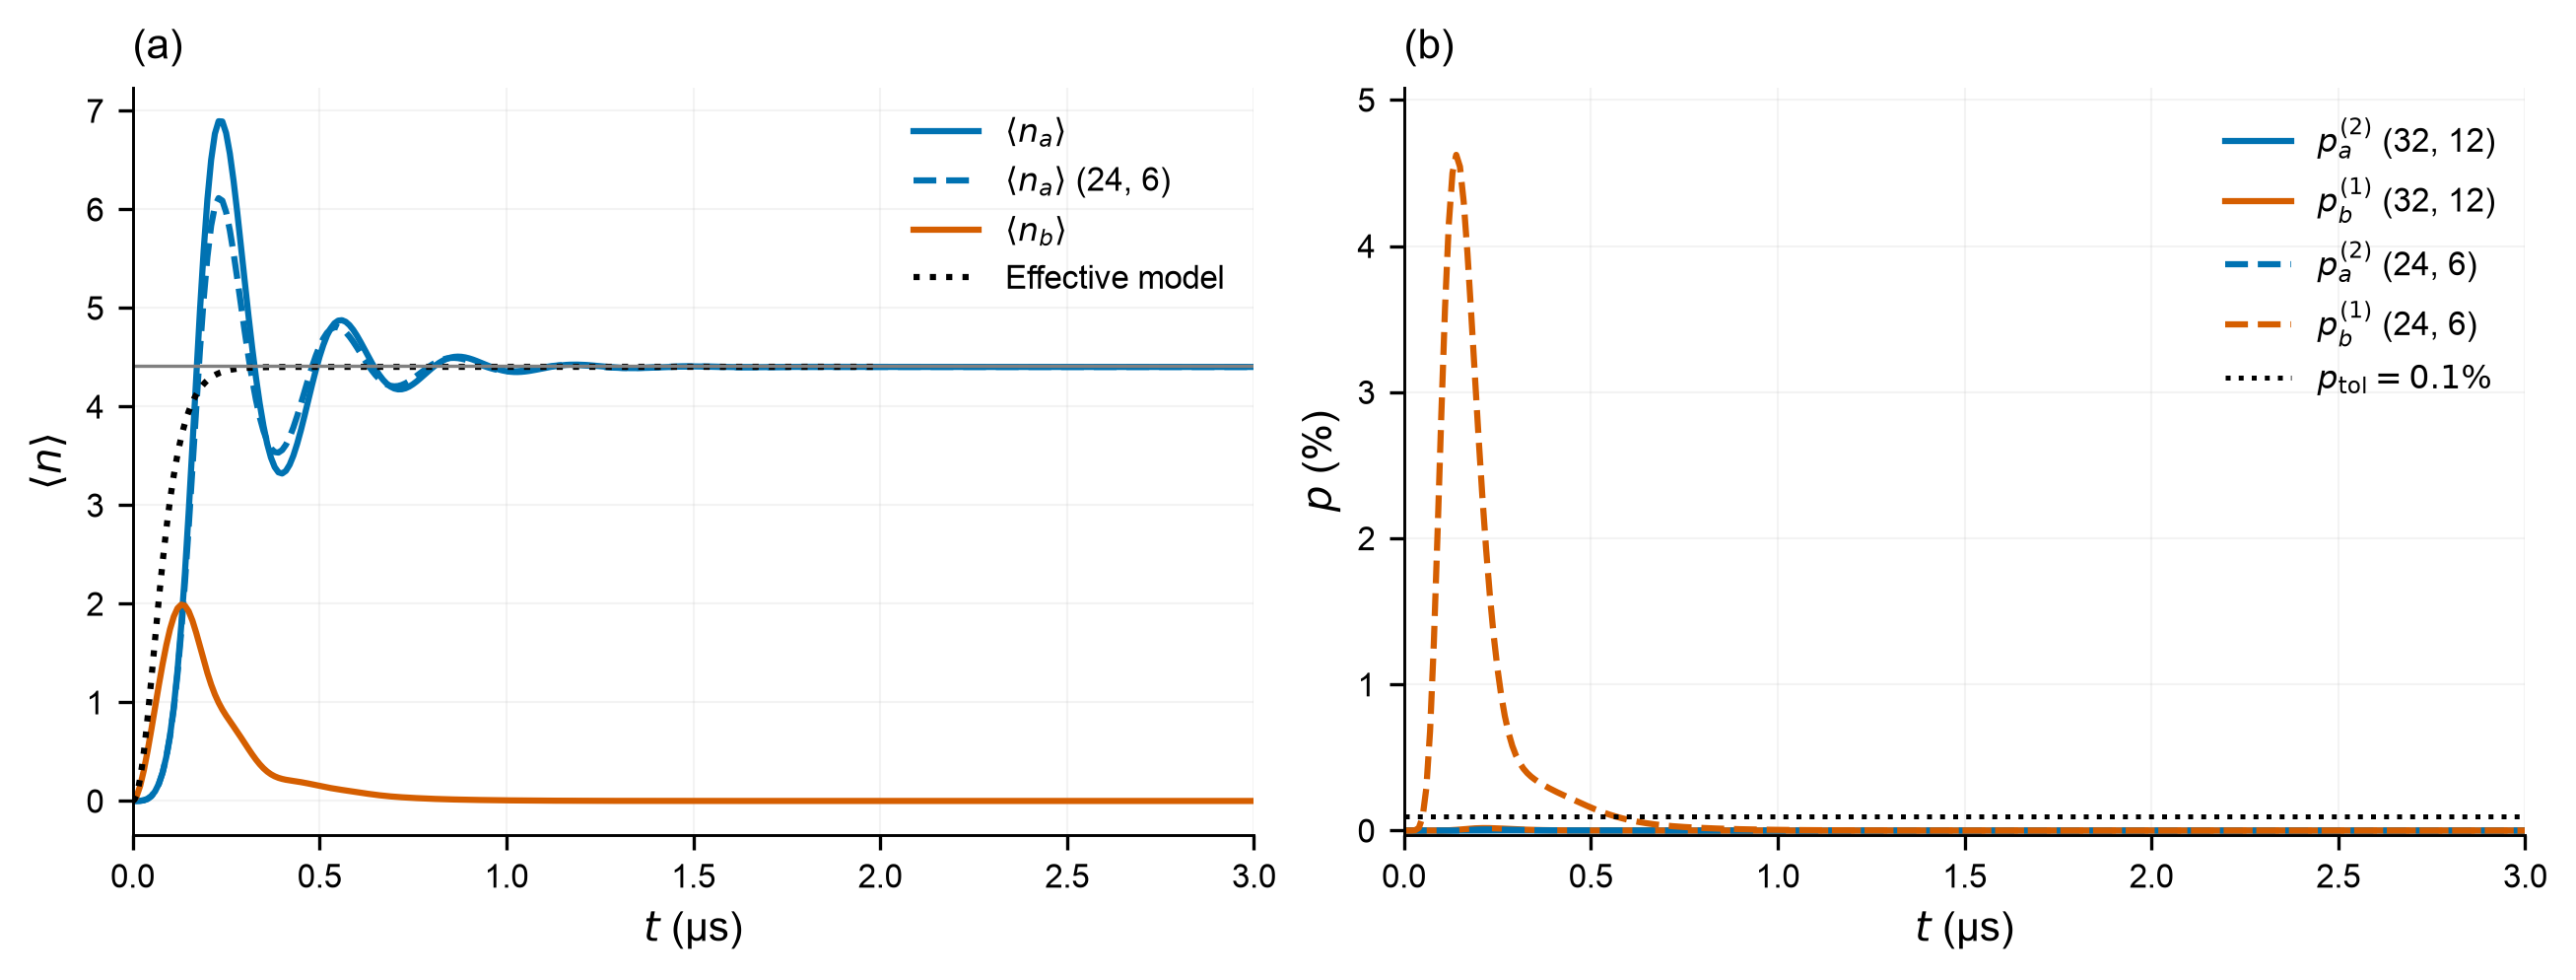

In [3]:
show('task_1_1_inflation', 1000)

**Two-mode inflation and Fock-space occupation.** (a) Memory and buffer occupations at $(N_a,N_b)=(32,12)$; the dashed memory curve uses $(24,6)$ (start). The dotted curve is the effective one-mode prediction, and the horizontal line marks $\alpha^2$. (b) Full-range top-level probabilities over 0–3 µs, in percent: $p_a^{(2)}$ sums the probabilities of memory levels $N_a-2$ and $N_a-1$; $p_b^{(1)}$ is the probability of buffer level $N_b-1$. Solid and dashed curves use the same cutoffs as in (a). The dotted line marks our chosen 0.1% tolerance for convergence checks. The $(24,6)$ buffer peak reaches 4.62%, while both $(32,12)$ monitors remain below the tolerance throughout inflation. The buffer monitor is $n_b=5$ for $N_b=6$ and $n_b=11$ for $N_b=12$.

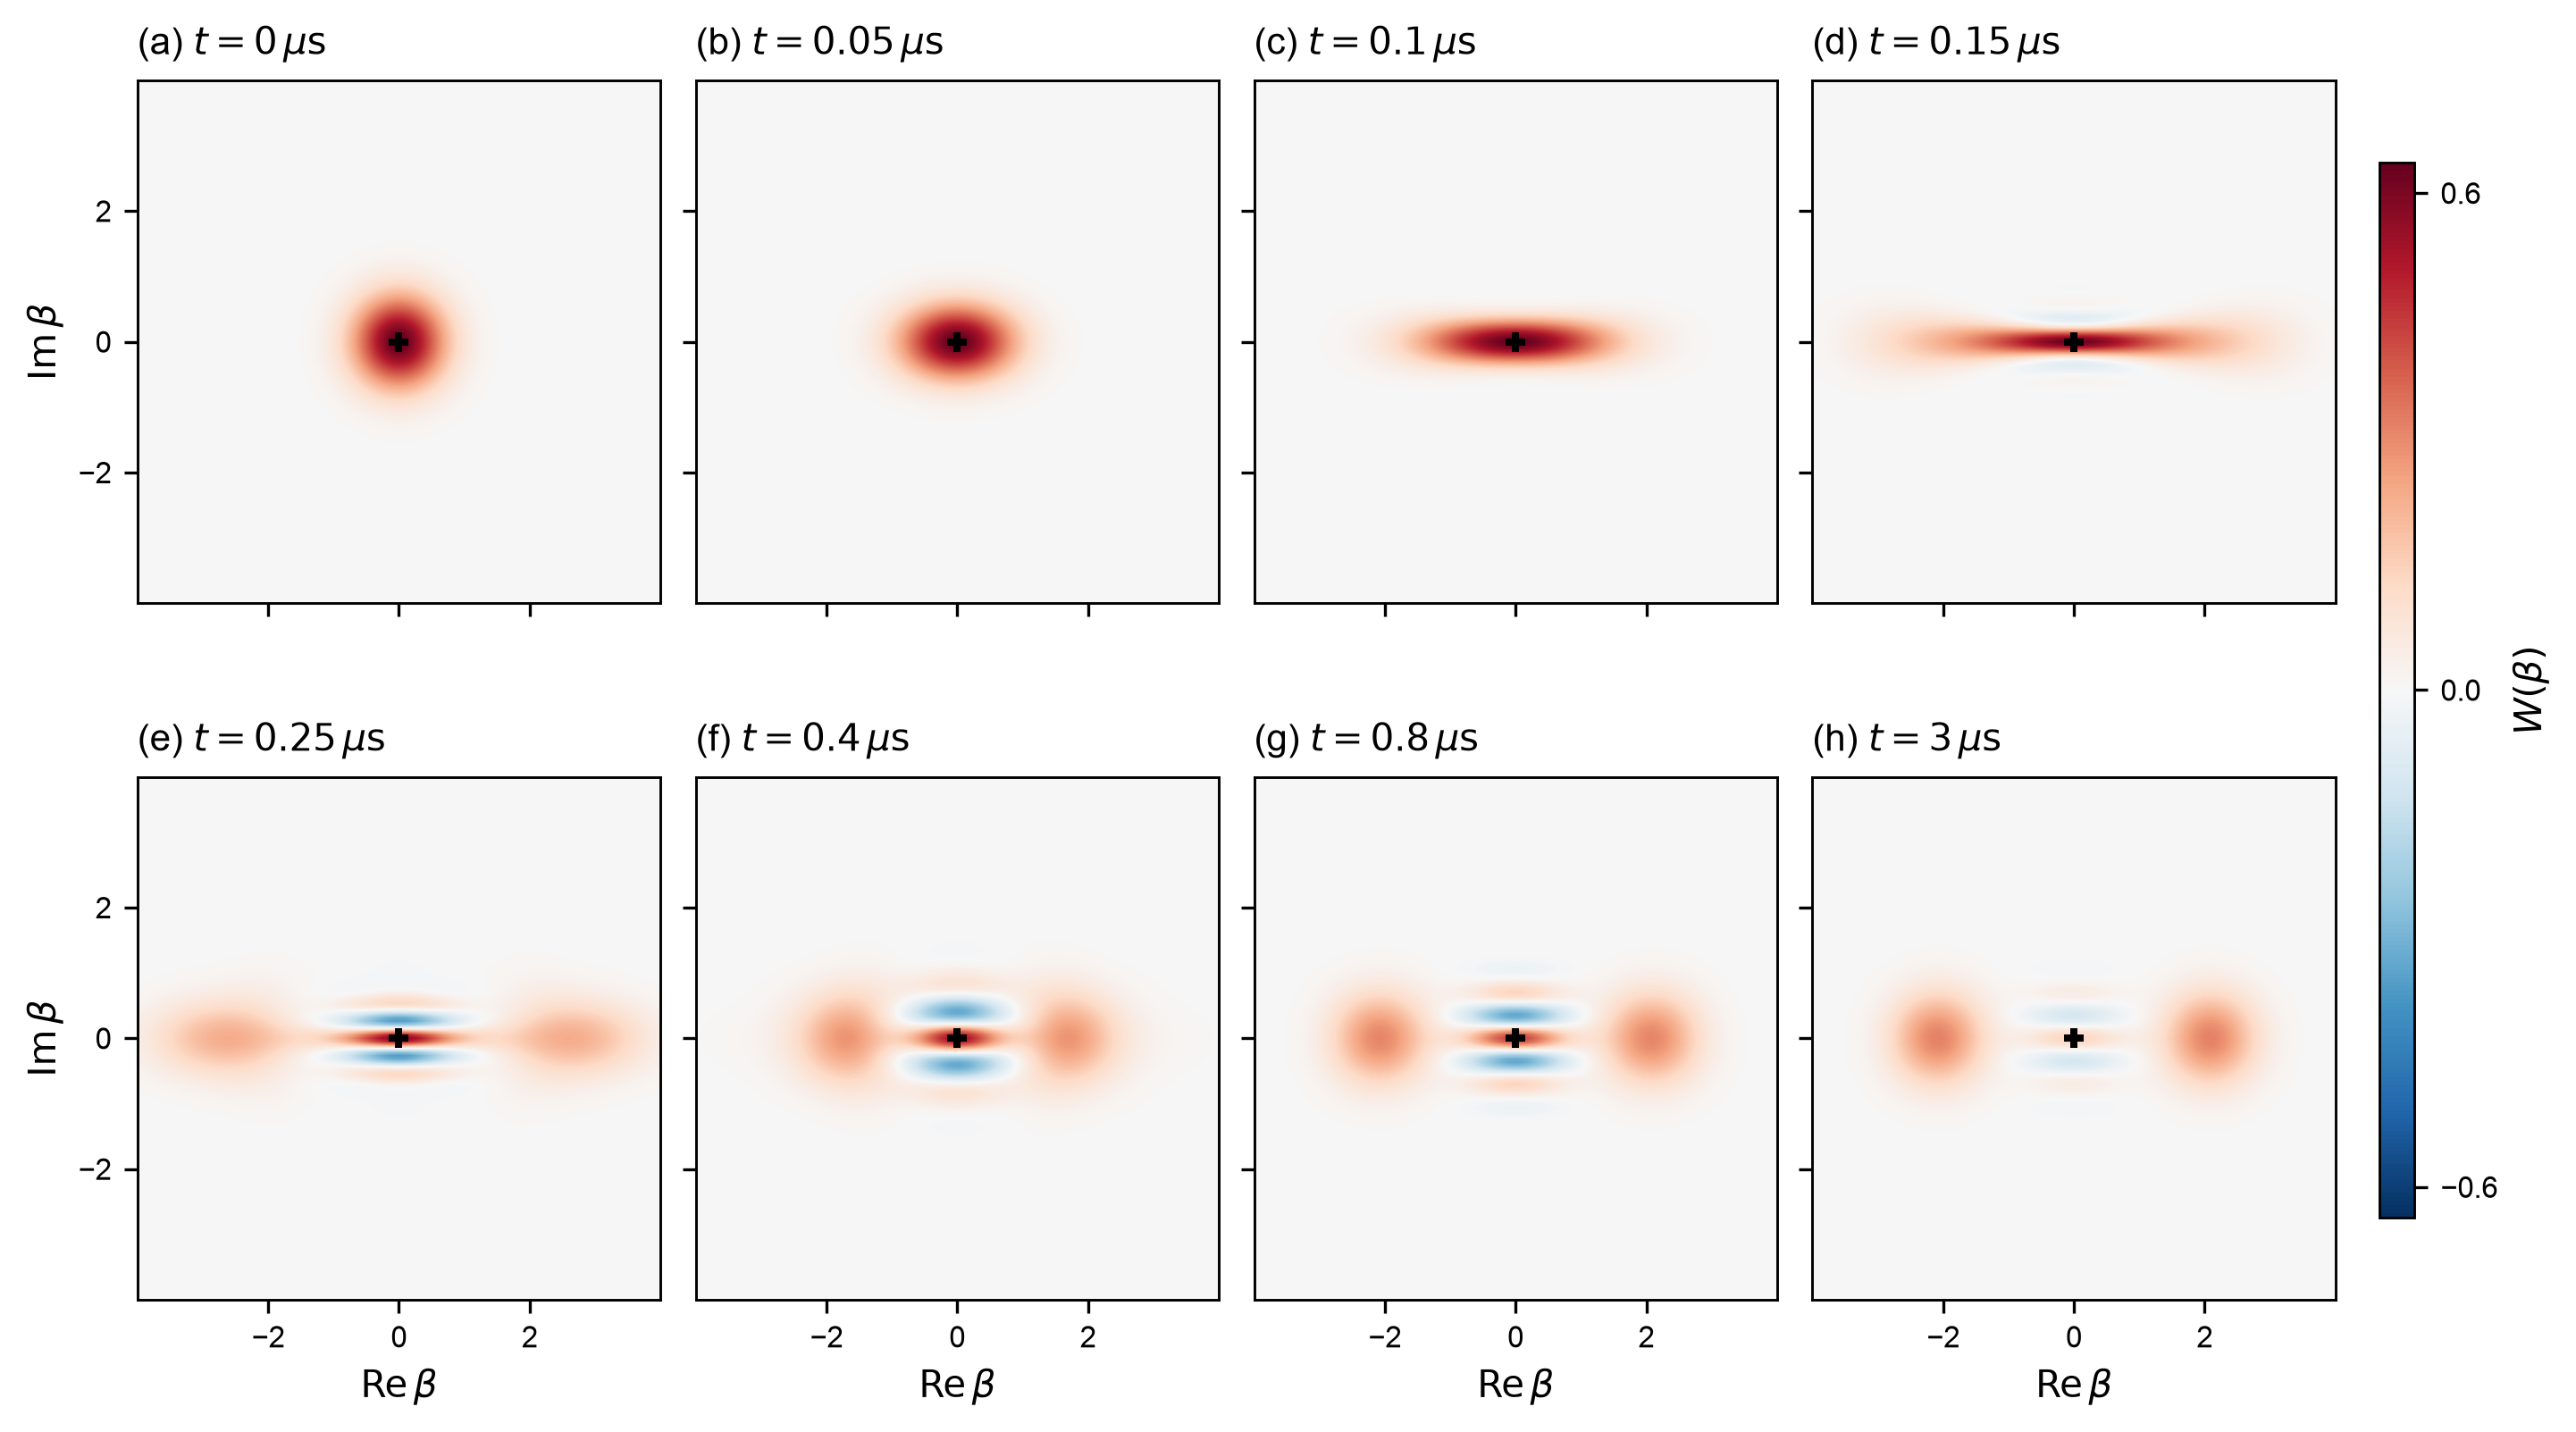

In [4]:
show('task_1_1_wigner', 1100)

**Memory-state evolution in the two-mode model.** Wigner functions of the reduced memory state $\rho_a=\mathrm{Tr}_b\rho$ at the indicated times, for $(N_a,N_b)=(32,12)$ and an initial vacuum. The coordinate $\beta$ is the complex phase-space amplitude. All panels share the normalized scale $-2/\pi\leq W\leq2/\pi$.

[Animated evolution](../figures/task_1_1_wigner.gif)

## Numerical diagnostics

The main figure uses a linear probability scale. The logarithmic view below is supplementary. Physical ringdown persists under tighter tolerances and independent integration; the near-well estimate of its period is 0.319 µs, consistent with the observed 0.31–0.32 µs.

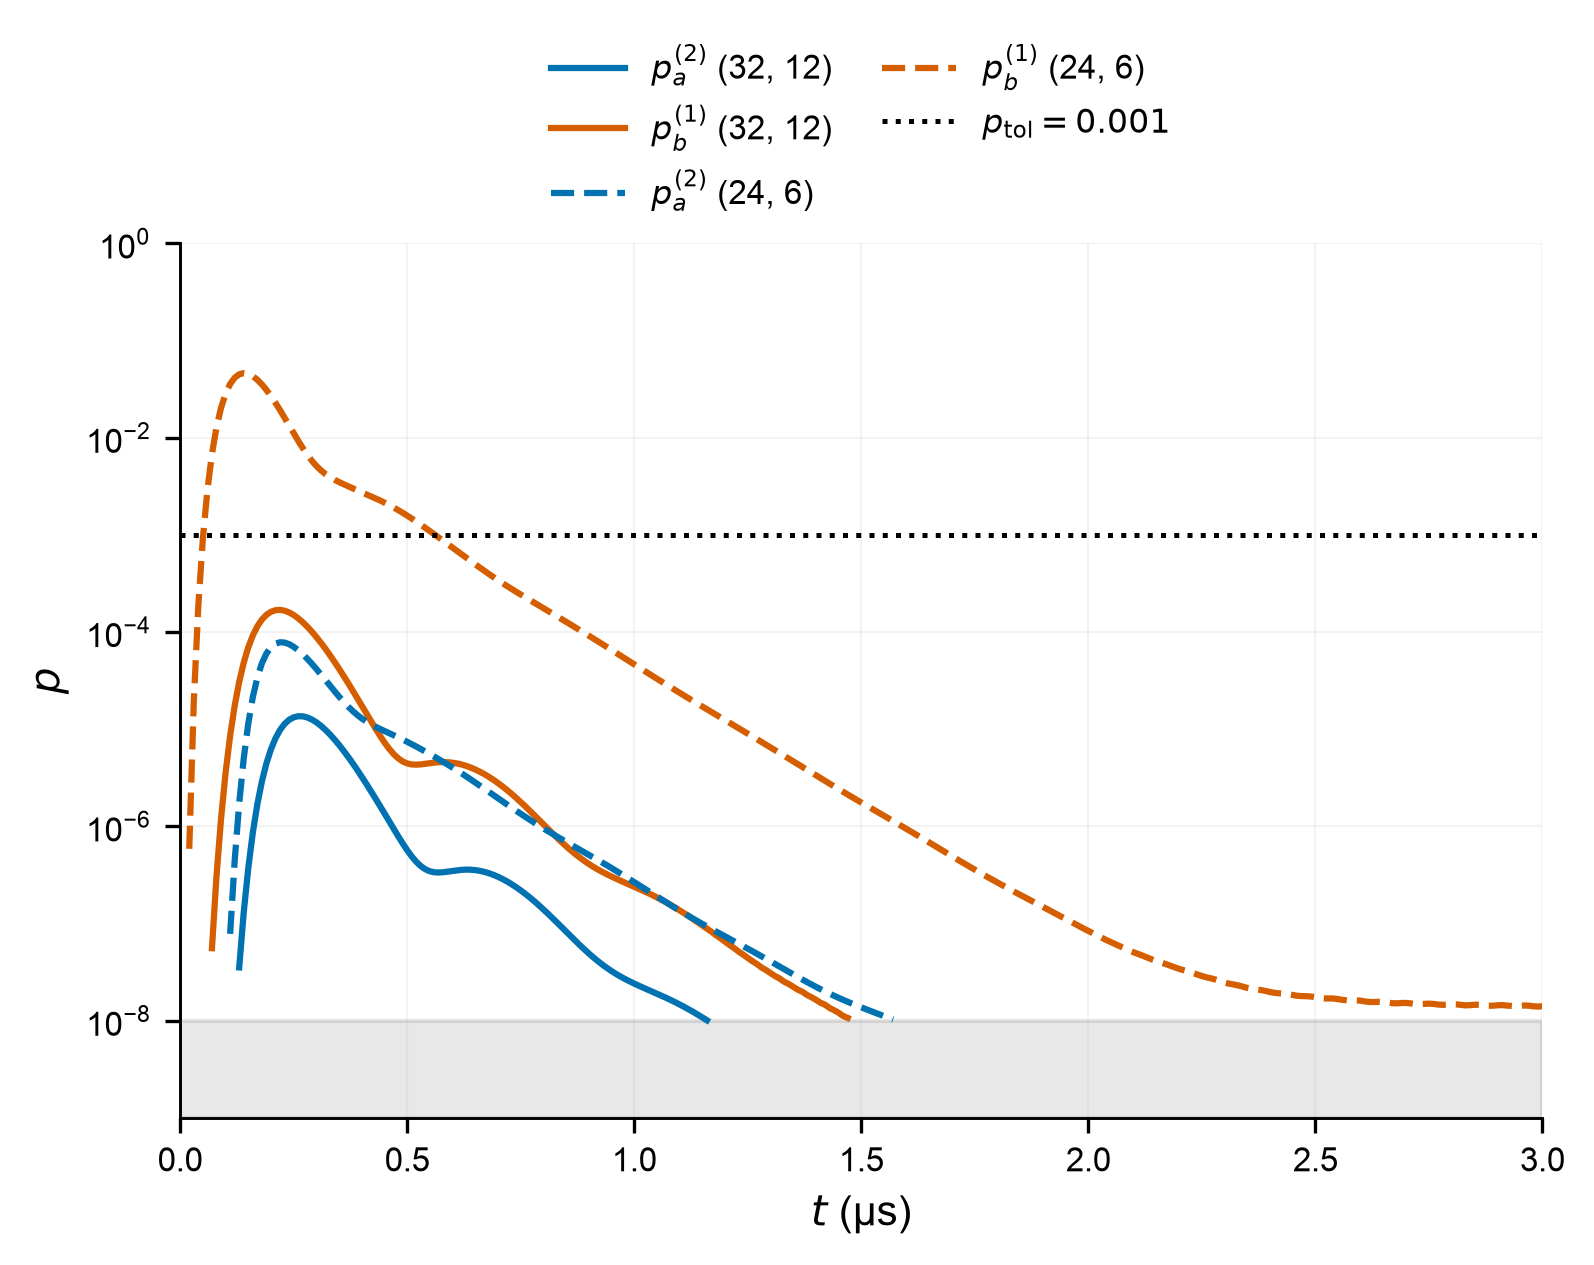

In [5]:
show('task_1_1_truncation_log', 800)

**Top-level occupation across scales.** The probabilities $p_a^{(2)}$ and $p_b^{(1)}$ defined in the inflation figure, for $(32,12)$ and $(24,6)$ (start), displayed as fractions. The dotted line is the chosen numerical tolerance $p_\mathrm{tol}=10^{-3}$. Values below $10^{-8}$ are omitted from the logarithmic curves; the shaded band marks this unresolved range. Signed solver residuals are retained in the numerical audit, without clipping or smoothing the underlying data.

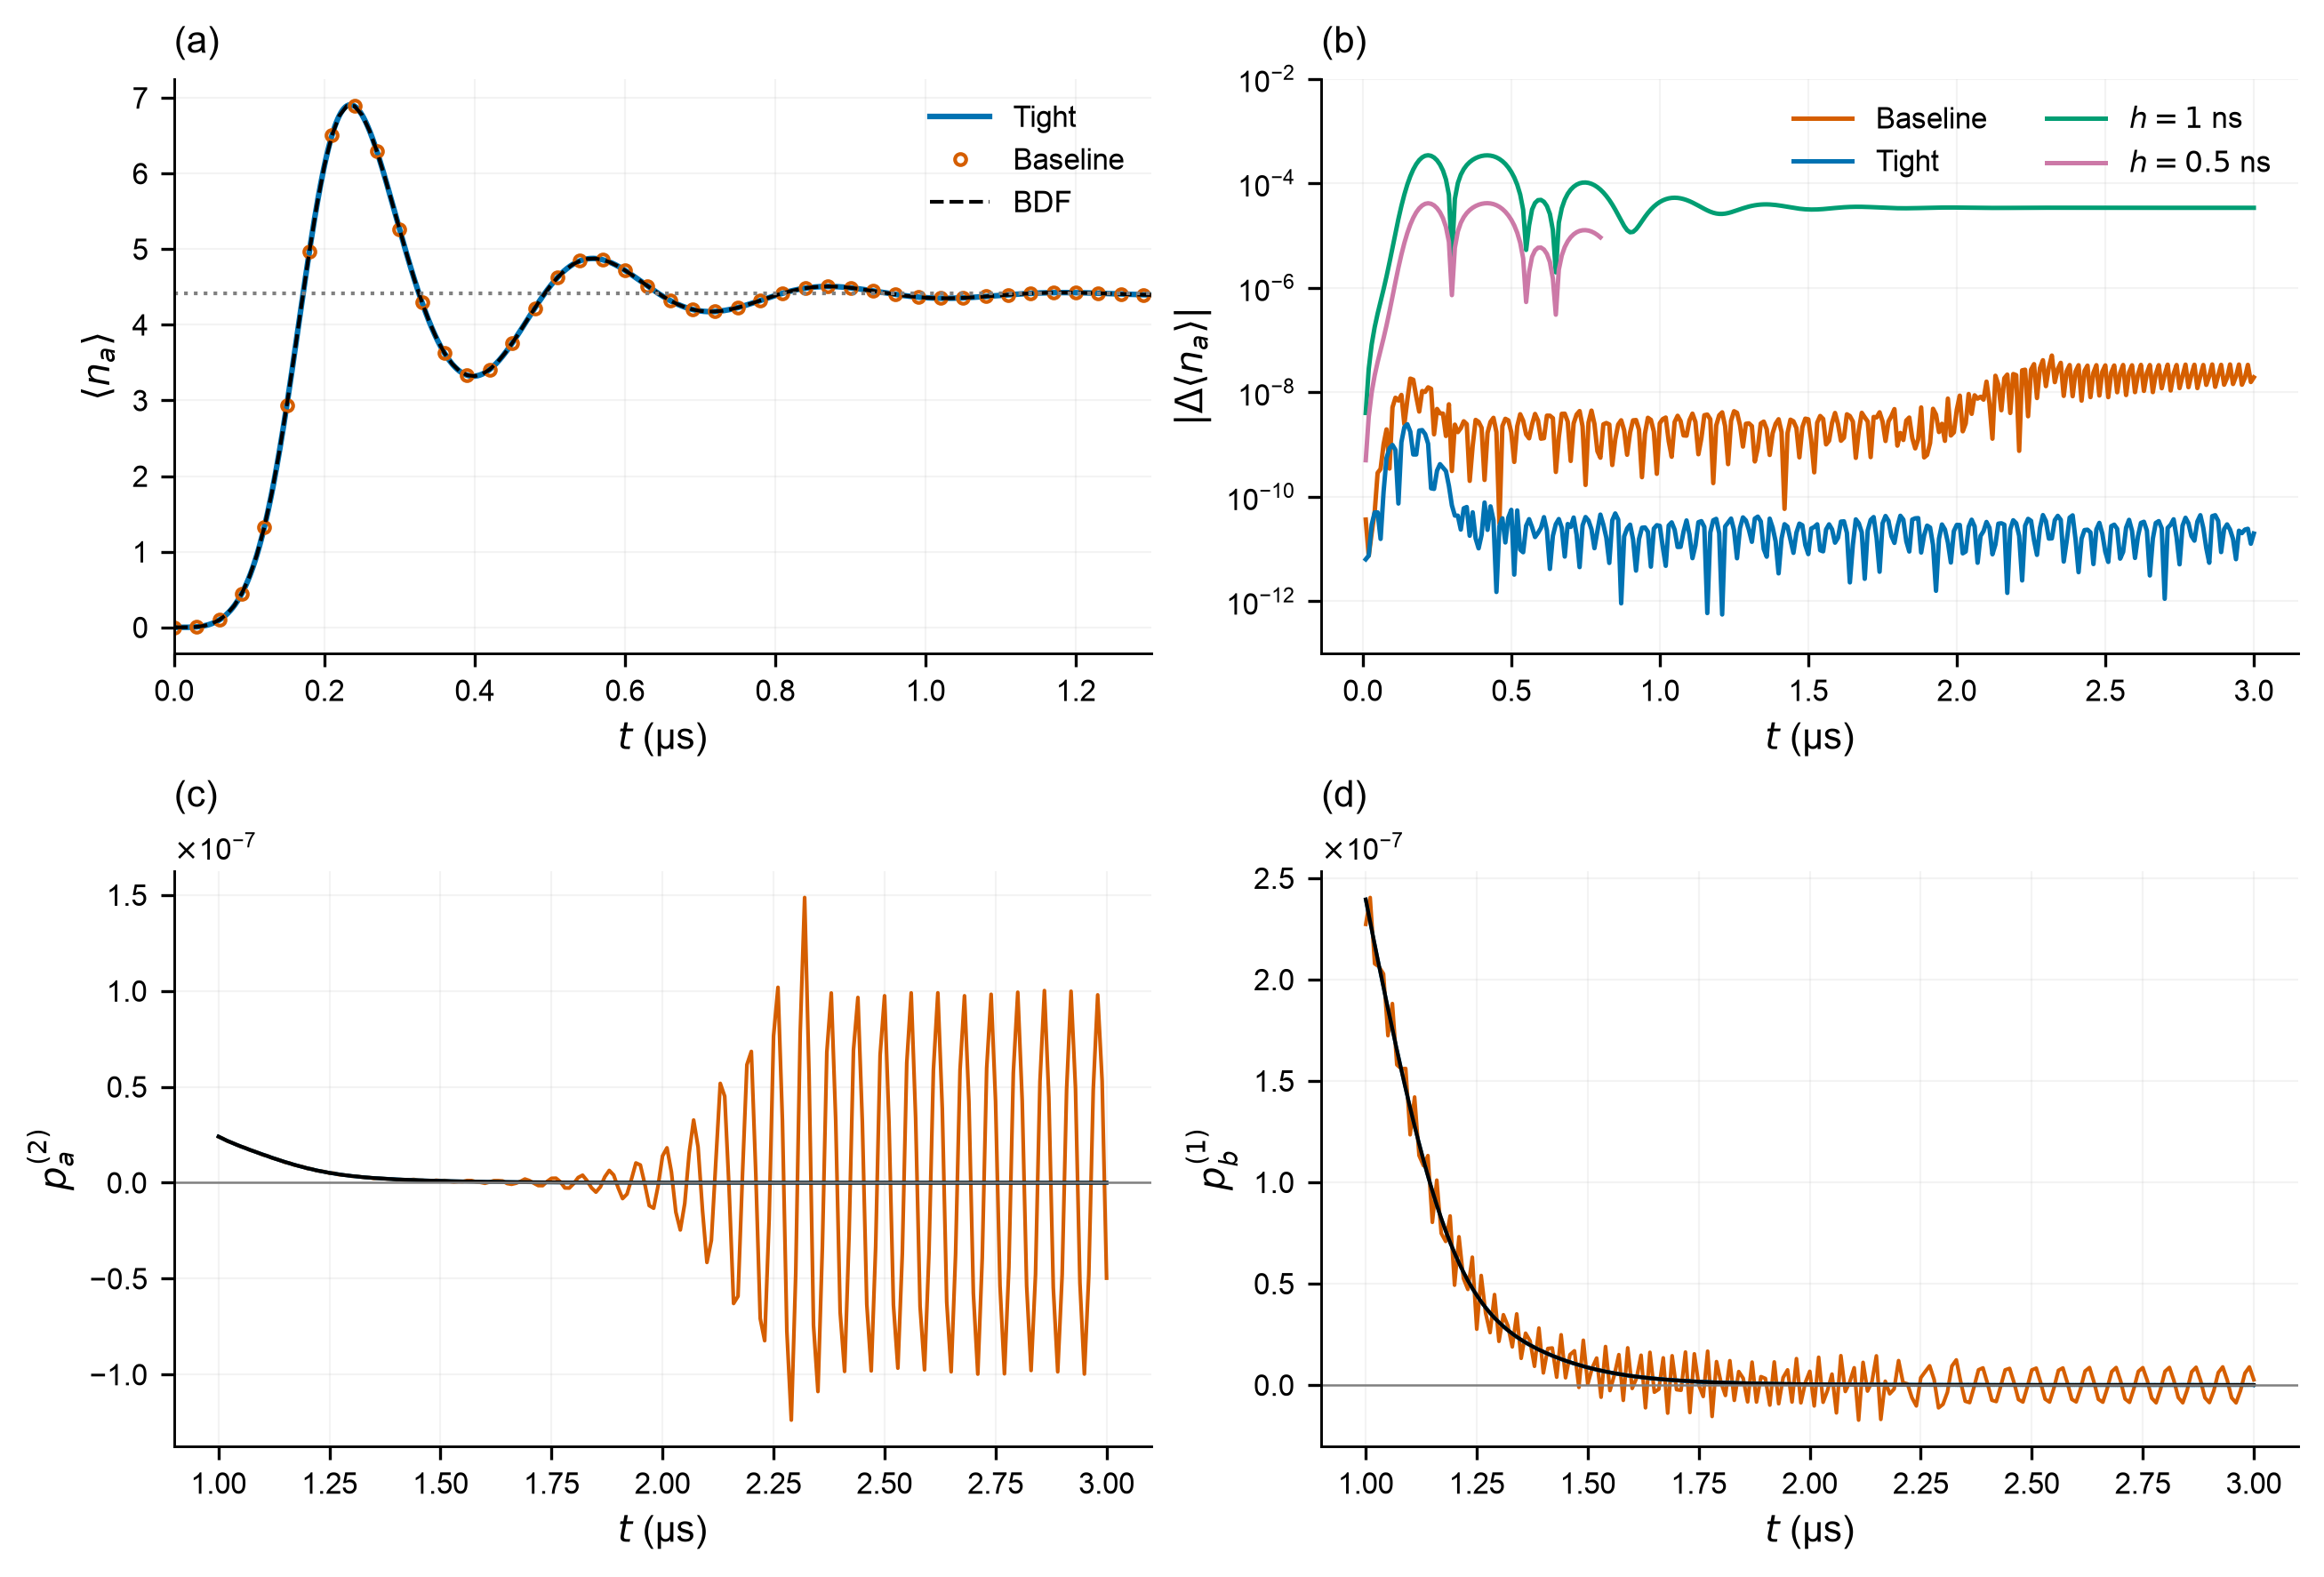

In [6]:
show('task_1_1_numerical_checks', 1050)

**Integration checks for two-mode inflation.** (a) Memory occupation from baseline and tight adaptive integration and an independent BDF solver. (b) Absolute difference from BDF, including fixed-step Rouchon3 calculations with steps $h=1$ and $0.5$ ns; the latter extends to $0.8$ µs. (c,d) Raw signed estimates of $p_a^{(2)}$ and $p_b^{(1)}$ after $1$ µs. Baseline tolerances are $(\mathrm{rtol},\mathrm{atol})=(10^{-8},10^{-10})$; tight tolerances are $(10^{-10},10^{-12})$. Saved intervals are 10 ns for baseline/BDF and 1 ns for tight integration. Negative population estimates expose numerical residuals. All runs use $(N_a,N_b)=(32,12)$.

In [7]:
load('task_1_1_checks')['checks']

{'save_grid_does_not_change_photon_solution': True,
 'tight_solver_matches_independent_bdf': True,
 'fixed_step_halving_reduces_error': True}